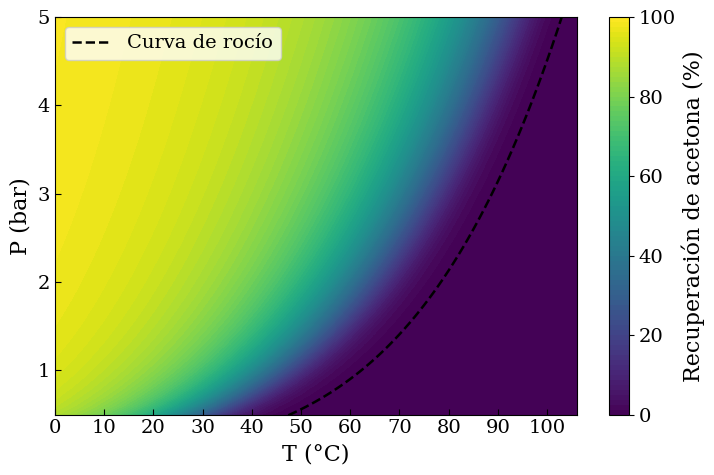

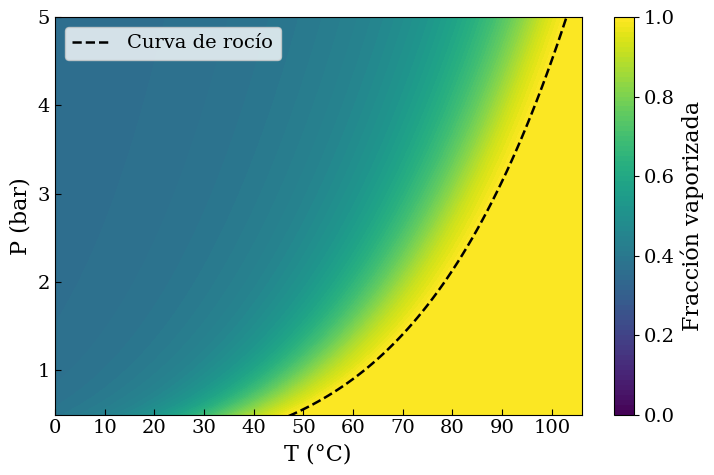

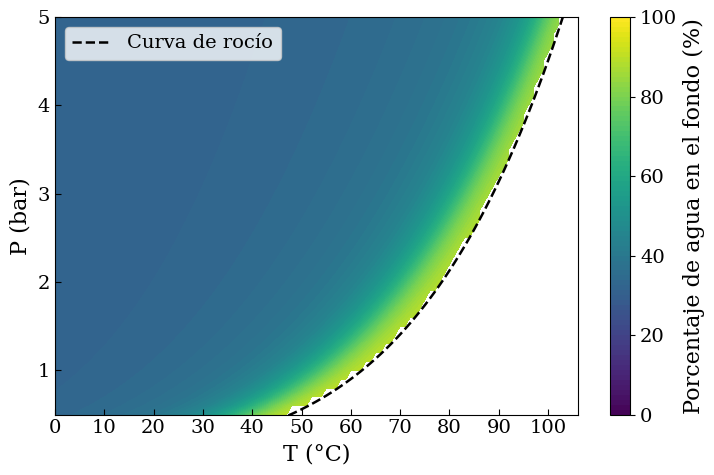

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import root

from properties import get_mixture
from equilibrium import gamma_NRTL, Px_dew_NRTL
from flash import of_torre, is_physical, flash_newton_damped

###############
# DATA
###############

components = ["IPA", "Water", "Acetone"]
fn_psats, nrtl_params, _ = get_mixture(components)
z = np.array([0.0998, 0.2038, 0.3482, 0.3482])  # From mass balance

# Creates T,P grid
Ts = np.arange(273.15, 380.1, 1.0)
Ps = np.arange(0, 5.01, 0.1)


#################################################
# P_DEW CURVE
#################################################

P_dew = np.full(len(Ts), np.nan)
x_dew = np.full((len(Ts), 3), np.nan)

P_guess = 1.0

for j, T in enumerate(Ts):
    P, x = Px_dew_NRTL(T, z[:-1], fn_psats, nrtl_params, P_guess=P_guess)
    P_dew[j] = P
    x_dew[j] = x

    P_guess = P


beta_map = np.full((len(Ps), len(Ts)), np.nan)
x_map = np.full((len(Ps), len(Ts), 3), np.nan)

# 0 = Vapor, 1 = Líquido + vapor, 2 = Fallo
phase_map = np.zeros((len(Ps), len(Ts)), dtype=int)

x_feed = z[:3] / np.sum(z[:3])

for i, P in enumerate(Ps):
    for j, T in enumerate(Ts):
        if not np.isfinite(P_dew[j]):
            phase_map[i, j] = 2
            continue
        if P <= P_dew[j]:
            continue
        F = lambda u: of_torre(
            u, T, P, z, fn_psats, nrtl_params
        )
        guesses = []
        # Neighbour solutions
        if i > 0 and phase_map[i-1, j] == 1:
            guesses.append(
                np.r_[x_map[i-1, j, :2], beta_map[i-1, j]]
            )
        if j > 0 and phase_map[i, j-1] == 1:
            guesses.append(
                np.r_[x_map[i, j-1, :2], beta_map[i, j-1]]
            )

        # Guesses around dew
        for b in [0.999, 0.98, 0.90]:
            guesses.append(np.r_[x_dew[j, :2], b])

        # General guesses
        for b in [0.5, 0.7, 0.85]:
            guesses.append(np.r_[x_feed[:2], b])

        phase_map[i, j] = 2

        for u0 in guesses:
            if not is_physical(u0, z):
                continue
            try:
                u = flash_newton_damped(F, u0, z)
                if np.max(np.abs(F(u))) < 1e-8:
                    beta_map[i, j] = u[-1]
                    x_map[i, j] = np.r_[u[:2], 1 - np.sum(u[:2])]
                    phase_map[i, j] = 1
                    break
            except (RuntimeError, ValueError, np.linalg.LinAlgError):
                pass


#########################
# DATA EXTRACTION
#########################

recovery_map = np.full_like(beta_map, np.nan)
fvap_map = np.full_like(beta_map, np.nan)

# Vapor
recovery_map[phase_map == 0] = 0
fvap_map[phase_map == 0] = 1

# VLE
mask = phase_map == 1

recovery_map[mask] = (
    100 * (1 - beta_map[mask])
    * x_map[:, :, 2][mask] / z[2]
)

fvap_map[mask] = beta_map[mask]

# Water
water_map = np.full_like(beta_map, np.nan)
water_map[mask] = 100 * x_map[:, :, 1][mask]


#########################
# GRAPHS
#########################

from matplotlib.ticker import MultipleLocator

plt.rcParams.update({
    "font.family": "serif",
    "font.size": 15,
    "axes.labelsize": 16,
    "xtick.labelsize": 14,
    "ytick.labelsize": 14,
    "legend.fontsize": 14,
    "svg.fonttype": "path"
})

T_C = Ts - 273.15

figures = [
    (
        recovery_map,
        "Recuperación de acetona (%)",
        "recuperacion_acetona_V402.pdf",
        0, 100
    ),
    (
        fvap_map,
        "Fracción vaporizada",
        "fraccion_vaporizada_V402.pdf",
        # z[3], 1
        0, 1
    ),
    (
        water_map,
        "Porcentaje de agua en el fondo (%)",
        "fraccion_agua_liquido_V402.pdf",
        0, 100
    )
]

for data, label, filename, vmin, vmax in figures:

    fig, ax = plt.subplots(figsize=(7.5, 5))

    im = ax.contourf(
        T_C, Ps, data,
        levels=np.linspace(vmin, vmax, 81),
        cmap="viridis",
    )

    ax.plot(
        T_C, P_dew,
        color="black",
        linestyle="--",
        linewidth=1.8,
        label="Curva de rocío"
    )
    ax.set_xlabel("T (°C)")
    ax.set_ylabel("P (bar)")

    ax.set_xlim(T_C.min(), T_C.max())
    ax.set_ylim(Ps.min(), Ps.max())

    ax.legend()

    ticks = np.linspace(vmin, vmax, 6)
    cbar = fig.colorbar(im, ax=ax, ticks=ticks, format="%.0f" if vmax == 100 else "%.1f")
    cbar.set_label(label, fontsize=16)
    cbar.ax.tick_params(labelsize=14)

    ax.xaxis.set_major_locator(MultipleLocator(10))
    ax.yaxis.set_major_locator(MultipleLocator(1))

    ax.tick_params(direction="in", length=4)

    ax.set_ylim(0.5, 5.0)
    plt.tight_layout()
    plt.savefig(filename, bbox_inches="tight")
    plt.show()